# Which workers will benefit from closing the Productivity Pay Gap?
Code for [the article](https://neillinehan.substack.com/p/which-workers-will-benefit-from-closing). All data is pulled live; needs a free [FRED API key](https://fredaccount.stlouisfed.org/apikey) saved in Colab Secrets as `FRED`.

### Data compiling

In [1]:
#every source is pulled live each run
import io, os, datetime
import requests
import pandas as pd

def fetch_url(url):
    r = requests.get(url, timeout=120, headers={'User-Agent': 'Mozilla/5.0'})
    r.raise_for_status()
    if r.content.lstrip()[:15].lower().startswith((b'<!doctype', b'<html')):
        raise ValueError(f'{url} returned a web page instead of a data file')
    return r.content

In [2]:
%pip install -q fredapi xlrd

#### EPI replication

In [3]:
import io
import pandas as pd
import numpy as np
import datetime
from fredapi import Fred

#FRED API key: Colab Secrets (name: FRED), or the FRED_API_KEY environment variable when running locally
try:
    from google.colab import userdata
    FRED_KEY = userdata.get('FRED')
except ImportError:
    FRED_KEY = os.environ['FRED_API_KEY']
fred = Fred(api_key=FRED_KEY)

def fetch_fred_series(series_map, start_date):
    data_frames = []
    for ticker, name in series_map.items():
        series = fred.get_series(ticker, observation_start=start_date)
        series.name = name
        data_frames.append(series)

    # Concatenate all series into a single DataFrame
    return pd.concat(data_frames, axis=1)

def combine_data(bls_pay_csv, bls_hours_csv, bea_csv, prices_csv):
    start = datetime.datetime(1948, 1, 1)

    # 1. Unified External Data Retrieval
    series_map = {
        'CES0500000006': 'workers', #thousands
        'AWHNONAG': 'weekly_hours', #weekly hours
        'A362RC1Q027SBEA':'ndp', #billions - NIPA
    }
    comp_series = {
        'CES1000000006': 'mine_emp', #thousands
        'CES1000000007': 'mine_hrs', #weekly hours
        'CES2000000006': 'cons_emp', #thousands
        'CES2000000007': 'cons_hrs', #weekly hours
        'CES3000000006': 'mfg_emp',  #thousands
        'AWHMAN': 'mfg_hrs' #weekly hours
    }

    all_fred_series = {**series_map, **comp_series}
    fred_data = fetch_fred_series(all_fred_series, start).rename(columns=all_fred_series)

    # 2. Historical Bridge Calculations
    #production & nonsupervisory hours only start in 1964, so before then they're estimated
    #from mining, construction and manufacturing hours, scaled by their ratio over 1964-1973
    fred_data['goods_agg_hrs'] = (
        (fred_data['mine_emp'] * fred_data['mine_hrs']) +
        (fred_data['cons_emp'] * fred_data['cons_hrs']) +
        (fred_data['mfg_emp'] * fred_data['mfg_hrs'])
    )
    fred_data['total_p_n_agg'] = fred_data['workers'] * fred_data['weekly_hours'] #weekly thousand hours

    overlap = fred_data.loc['1964-01-01':'1973-12-01']
    bridge_ratio = (overlap['total_p_n_agg'] / overlap['goods_agg_hrs']).mean()

    fred_data['total_hours_workers'] = fred_data['total_p_n_agg'].combine_first(fred_data['goods_agg_hrs'] * bridge_ratio)  #weekly thousand hours

    # Compress high-frequency data to quarterly tracking coordinates
    fred_q = fred_data.resample('QS').mean().ffill()
    fred_q['year'] = fred_q.index.year
    fred_q['quarter'] = fred_q.index.quarter
    fred_q['frequency'] = 'quarterly'

    # 3. Import and Shape Local Source Files
    clean_bea = pd.read_csv(bea_csv).pivot(
        index=['year', 'quarter', 'frequency'], columns='name', values='value'
    ).reset_index()
    clean_bea['nipa_comp_wage_ratio'] = clean_bea['nipa_comp'] / clean_bea['nipa_wage'] #unitless

    bls_hours = pd.read_csv(bls_hours_csv)
    productivity = pd.merge(
        clean_bea[['year', 'quarter', 'frequency', 'nipa_ndp']],
        bls_hours, on=['year', 'quarter', 'frequency'], how='inner'
    )
    productivity['productivity_nominal'] = productivity['nipa_ndp'] / productivity['hours_millions'] #$, EPI's all-employee version, only used to keep the quarters EPI has

    bls_pay = pd.read_csv(bls_pay_csv).rename(columns={'value': 'bls_prod_wage_nominal'}) #$/h
    prices = pd.read_csv(prices_csv).rename(columns={'c_cpi_u': 'cpi'})[['year', 'quarter', 'frequency', 'cpi']]

    # 4. Consolidated Matrix Alignment (Wide-Format Merging)
    combined = pd.merge(bls_pay, clean_bea[['nipa_ndp', 'year', 'quarter', 'frequency', 'nipa_comp_wage_ratio']], on=['year', 'quarter', 'frequency'])
    combined = combined.merge(fred_q, on=['year', 'quarter', 'frequency'], how='left')
    combined = combined.merge(productivity[['year', 'quarter', 'frequency', 'productivity_nominal']], on=['year', 'quarter', 'frequency'])
    combined = combined.merge(prices, on=['year', 'quarter', 'frequency'])

    combined.dropna(subset=['bls_prod_wage_nominal', 'productivity_nominal', 'cpi'], inplace=True)
    combined['comp_private_nominal'] = combined['bls_prod_wage_nominal'] * combined['nipa_comp_wage_ratio'] #pay plus benefits

    # 5. Establish Inflation Adjusters (the latest quarter's dollars)
    cpi_bases = combined.sort_values(['year', 'quarter']).groupby('frequency').tail(1)[['frequency', 'cpi']].rename(columns={'cpi': 'cpi_base'})
    combined = combined.merge(cpi_bases, on='frequency')
    combined['cpi_deflator'] = combined['cpi_base'] / combined['cpi']

    # 6. Transform Values From Nominal to Real Terms
    combined['pn_hours_millions'] = combined['total_hours_workers'] * 0.052 #annual million hours
    combined['productivity_nominal_pn'] = combined['nipa_ndp'] / combined['pn_hours_millions'] #$
    combined['comp_private_real'] = combined['comp_private_nominal'] * combined['cpi_deflator']
    combined['productivity_real_pn'] = combined['productivity_nominal_pn'] * combined['cpi_deflator']

    # Assign chronological sequence tracking as the physical index
    combined.dropna(subset=['year', 'quarter'], inplace=True)
    combined['Date'] = pd.PeriodIndex.from_fields(year=combined['year'].astype(int), quarter=combined['quarter'].astype(int), freq='Q').to_timestamp()
    combined = combined.set_index('Date').sort_index()

    combined.drop(columns=['year', 'quarter', 'frequency'], errors='ignore', inplace=True)
    return combined

def run_pipeline():
    paths = {
        "bls_pay_csv": "https://raw.githubusercontent.com/Economic/productivity_pay_gap/main/data_outputs/bls_pay.csv",
        "bls_hours_csv": "https://raw.githubusercontent.com/Economic/productivity_pay_gap/main/data_outputs/bls_hours.csv",
        #EPI moved the raw API pulls to data_raw/ on 2026-10-22 (commit 12233bc); the other three files are still in data_outputs/
        "bea_csv": "https://raw.githubusercontent.com/Economic/productivity_pay_gap/main/data_raw/bea_api_output.csv",
        "prices_csv": "https://raw.githubusercontent.com/Economic/productivity_pay_gap/main/data_outputs/prices.csv",
    }
    print("Executing unified processing pipeline...")
    files = {arg: io.BytesIO(fetch_url(url)) for arg, url in paths.items()}
    return combine_data(**files)

final_df = run_pipeline()
last_hist_date = final_df.index[-1]

#the two series the whole article is built on, in real $ per hour of production & nonsupervisory work
B_hist = final_df['productivity_real_pn'] #"productivity"
w_hist = final_df['comp_private_real'] #pay incl. benefits
sigma = B_hist - w_hist #the productivity-pay gap
print(f'data runs {final_df.index[0].date()} to {last_hist_date.date()}, in {last_hist_date.year} Q{last_hist_date.quarter} dollars')

Executing unified processing pipeline...
data runs 1948-01-01 to 2026-04-01, in 2026 Q2 dollars


# US Surplus Value math

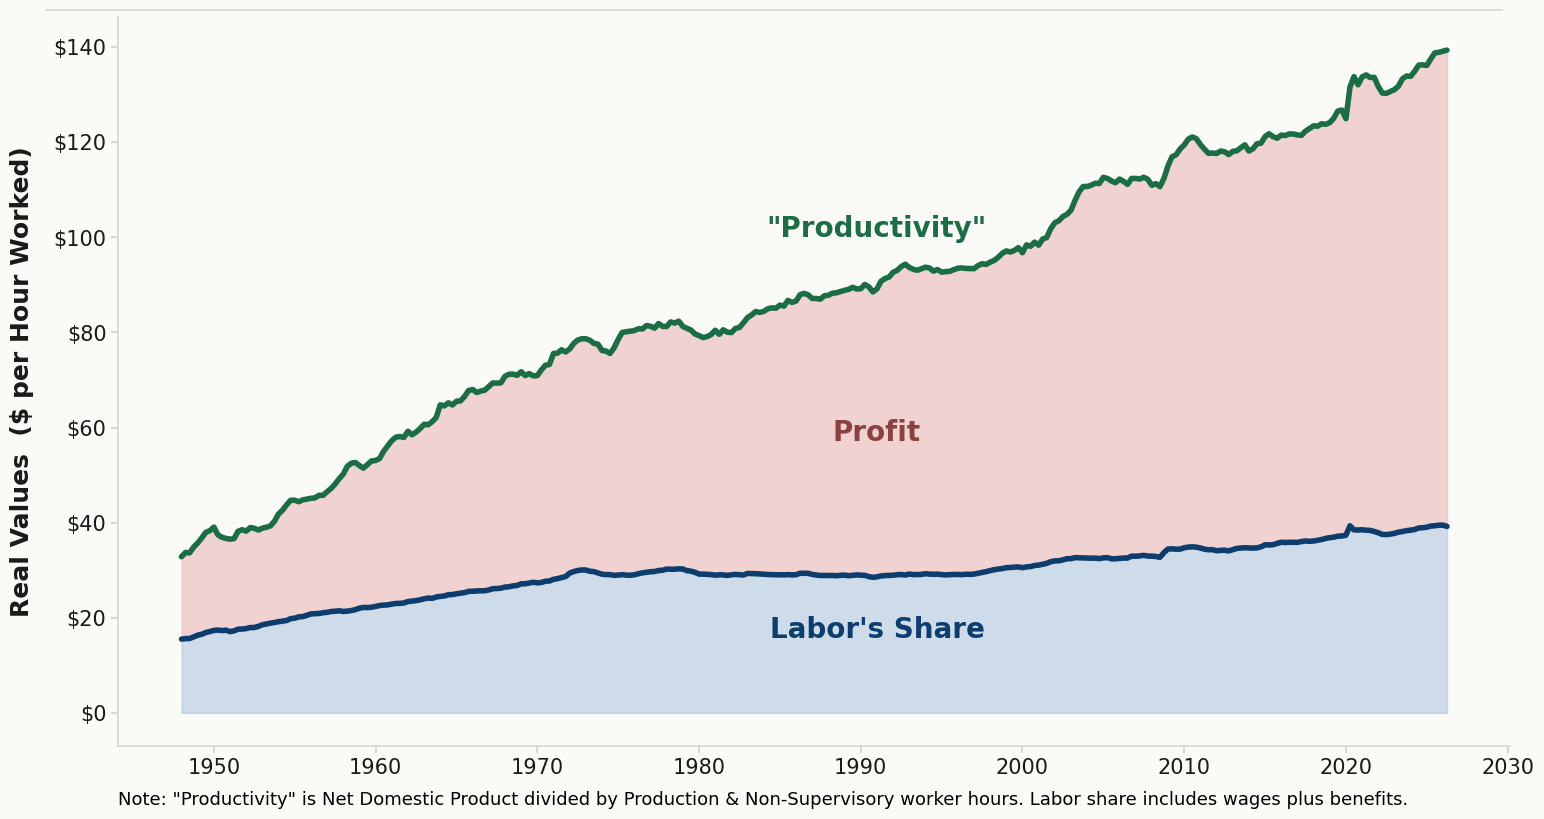

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.dates as mdates

# ── 1.  Colour Palette ────────────────────────────────────────────────────────
BG_COLOR   = '#FAFAF7'
PROD_COLOR = '#1B6E44'
WAGE_COLOR = '#0D3D6E'
SURP_FILL  = '#E8B4B0'
WAGE_FILL  = '#A8C4DC'
GRID_COLOR = '#D8D8D0'
TEXT_COLOR = '#1A1A1A'

# ── 2.  Figure (16 × 9 landscape) ────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(16, 9), facecolor=BG_COLOR)
ax.set_facecolor(BG_COLOR)

y_max = B_hist.max() * 1.10

# ── 3.  Shaded Areas ──────────────────────────────────────────────────────────
ax.fill_between(B_hist.index, 0, w_hist,
                color=WAGE_FILL, alpha=0.55, zorder=1)
ax.fill_between(B_hist.index, w_hist, B_hist,
                color=SURP_FILL, alpha=0.55, zorder=1)

# ── 4.  Lines ─────────────────────────────────────────────────────────────────
LW = 4.0   # main line width

ax.plot(B_hist.index, B_hist, color=PROD_COLOR, lw=LW, zorder=3,
        solid_capstyle='round')
ax.plot(w_hist.index, w_hist, color=WAGE_COLOR, lw=LW, zorder=3,
        solid_capstyle='round')

# ── 5.  In-Area Labels ────────────────────────────────────────────────────────
anno_date_hist = final_df.index[int(len(final_df) * 0.55)]
b_at = np.interp(mdates.date2num(anno_date_hist),
                 mdates.date2num(B_hist.index.to_pydatetime()), B_hist.values)
w_at = np.interp(mdates.date2num(anno_date_hist),
                 mdates.date2num(w_hist.index.to_pydatetime()), w_hist.values)

surp_mid_y = w_at + (b_at - w_at) * 0.5
ax.text(anno_date_hist, surp_mid_y, 'Profit',
        color='#7A2828', fontsize=20, fontweight='bold',
        ha='center', va='center', alpha=0.85)

# Line labels
ax.text(anno_date_hist, b_at + y_max * 0.03+5,
        '"Productivity"',
        color=PROD_COLOR, fontsize=20, fontweight='bold',
        ha='center', va='bottom')

w_val = w_hist.asof(anno_date_hist + pd.DateOffset(years=35))
ax.text(anno_date_hist, w_val-25,
        "Labor's Share",
        color=WAGE_COLOR, fontweight='bold', fontsize=20,
        ha='center', va='bottom')

# ── 6.  Axes & Grid ───────────────────────────────────────────────────────────
ax.yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))
ax.xaxis.set_major_locator(mdates.YearLocator(10))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

ax.tick_params(axis='both', which='major',
               labelsize=15, color=GRID_COLOR,
               labelcolor=TEXT_COLOR, length=5, width=1.5)
ax.spines[['top', 'right']].set_visible(False)
ax.spines['left'].set_color(GRID_COLOR)
ax.spines['bottom'].set_color(GRID_COLOR)
ax.spines['left'].set_linewidth(1.2)
ax.spines['bottom'].set_linewidth(1.2)
ax.set_ylabel('Real Values  ($ per Hour Worked)', fontsize=18,
              fontweight='bold', color=TEXT_COLOR, labelpad=14)

# Rule along the top
fig.add_artist(plt.Line2D([0.055, 0.965], [0.928, 0.928],
                           transform=fig.transFigure,
                           color=GRID_COLOR, lw=1.2))

# ── 7.  Source / Footnote ─────────────────────────────────────────────────────
fig.text(
    0.1, 0.04,
    'Note: "Productivity" is Net Domestic Product divided by Production & '
    'Non-Supervisory worker hours.'
    ' Labor share includes wages plus benefits.',
    fontsize=13, color='black', va='bottom', ha='left',
    linespacing=1.4
)

fig.subplots_adjust(top=0.920, bottom=0.110, left=0.100, right=0.970)
plt.show()

### Finding: capitalized surplus (sM/r) tracks the S&P price index for over 78 years

In [5]:
#https://shillerdata.com/
#the download link on shillerdata.com changes every time the file is updated, so look up the current link each run
import re, requests
def get_shiller_url():
    page = requests.get('https://shillerdata.com/', timeout=60, headers={'User-Agent': 'Mozilla/5.0'}).text
    links = re.findall(r'(?:https?:)?//[^"\'\s<>]+/ie_data\.xls[^"\'\s<>]*', page)
    if not links:
        raise RuntimeError('Could not find the ie_data.xls link on https://shillerdata.com/')
    return 'https:' + links[0] if links[0].startswith('//') else links[0]

snp = pd.read_excel(io.BytesIO(fetch_url(get_shiller_url())), sheet_name='Data', skiprows=7, skipfooter=1)

# Explicitly format the numerical 'Date' column into YYYY.MM string format with two-digit months
# e.g., 1948.1 becomes '1948.10', 1948.01 becomes '1948.01'
snp['Date'] = snp['Date'].apply(lambda x: f"{int(x)}.{int(round((x - int(x)) * 100)):02d}" if pd.notna(x) else np.nan)
# Now convert the correctly formatted string to datetime objects
snp['Date'] = pd.to_datetime(snp['Date'], format='%Y.%m')
snp = snp.set_index('Date').loc['1948-01-01':]

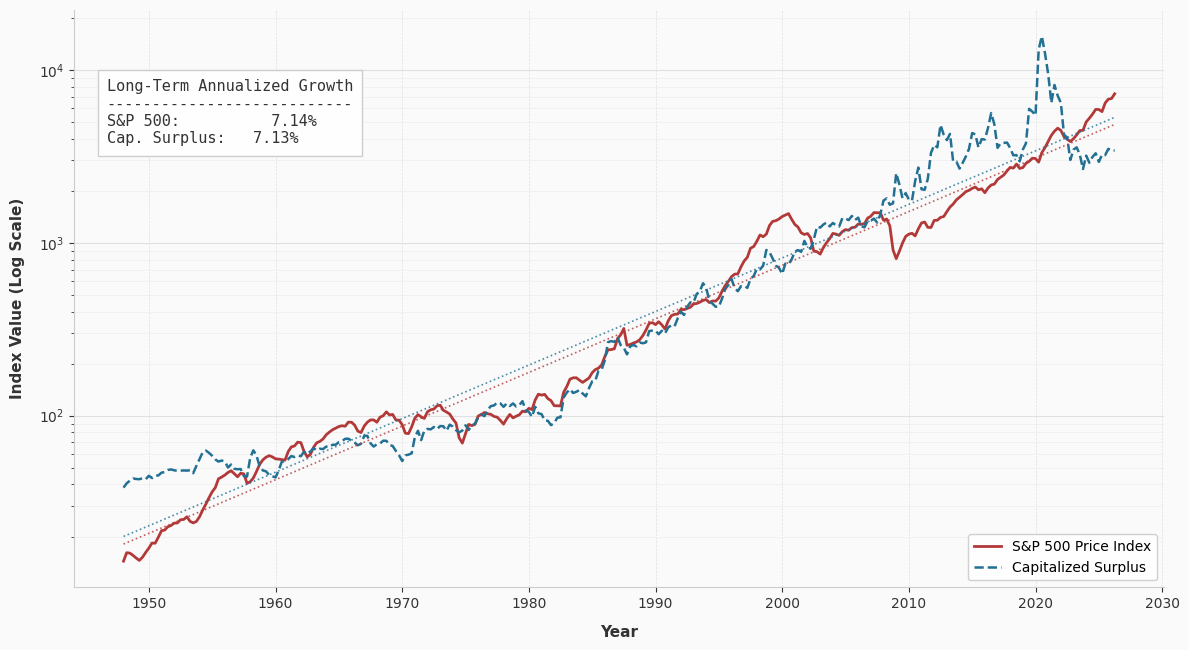

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress
# Subtract total P&N compensation from nominal NDP
surplus_nominal = ((final_df['ndp']*10**3 - final_df['comp_private_nominal'] * final_df['pn_hours_millions'])*1e6).rename('surplus_nominal')
# 1. Align data frequencies (Quarterly Start 'QS')
snp_quarterly = snp['P'].resample('QS').mean().loc['1948':]
surplus_quarterly = surplus_nominal.loc['1948':]

historical_rate = snp['Rate GS10'] #10-year Treasury rate, from the Shiller data
rate_quarterly = historical_rate.resample('QS').first().loc['1948':]

common_dates = surplus_quarterly.index.intersection(snp_quarterly.index).intersection(rate_quarterly.index)
sM = surplus_quarterly.loc[common_dates]
P = snp_quarterly.loc[common_dates]
r = rate_quarterly.loc[common_dates]

# 2. Compute capitalized surplus and apply historical 1948-1980 scaling
raw_capitalized = sM / (r / 100.0)
closed_phase = common_dates[common_dates < '1981-01-01']
scaling_factor =  P.loc[closed_phase].mean() / raw_capitalized.loc[closed_phase].mean()
capitalized_scaled = raw_capitalized * scaling_factor

# 3. Prepare variables for log linear regression
t = (common_dates - common_dates[0]).days / 365.25

# 4. Compute OLS Linear Regression Slopes
slope_P, intercept_P, _, _, _ = linregress(t, np.log(P))
slope_sM_r, intercept_sM_r, _, _, _ = linregress(t, np.log(capitalized_scaled))

growth_rate_P = slope_P * 100
growth_rate_sM_r = slope_sM_r * 100

# 5. Visualization
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'Helvetica', 'DejaVu Sans']

fig, ax = plt.subplots(figsize=(12, 7.5), facecolor='#FAFAFA')
ax.set_facecolor('#FAFAFA')

color_P = '#B33939'      # Deep Crimson for the empirical market price
color_sM = '#227093'     # Muted Slate Blue for the theoretical model
color_text = '#333333'   # Off-black for readable text

# Plot historical series
ax.plot(common_dates, P, label='S&P 500 Price Index', color=color_P, linewidth=2)
ax.plot(common_dates, capitalized_scaled, label='Capitalized Surplus', color=color_sM, linewidth=1.8, linestyle='--')

# Plot OLS Trendlines
ax.plot(common_dates, np.exp(intercept_P + slope_P * t), color=color_P, linestyle=':', linewidth=1.2, alpha=0.8)
ax.plot(common_dates, np.exp(intercept_sM_r + slope_sM_r * t), color=color_sM, linestyle=':', linewidth=1.2, alpha=0.8)

# Format Axes and Grid
ax.set_yscale('log')
ax.grid(True, which="major", axis='y', color='#E0E0E0', linestyle='-', linewidth=0.8)
ax.grid(True, which="minor", axis='y', color='#EBEBEB', linestyle='-', linewidth=0.4)
ax.grid(True, which="major", axis='x', color='#E0E0E0', linestyle='--', linewidth=0.5)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#CCCCCC')
ax.spines['bottom'].set_color('#CCCCCC')
ax.tick_params(colors=color_text, which='both')

ax.set_ylabel('Index Value (Log Scale)', fontsize=11, color=color_text, weight='bold', labelpad=10)
ax.set_xlabel('Year', fontsize=11, color=color_text, weight='bold', labelpad=10)

# Embed the long-run growth rates in the chart
text_str = (
    f"Long-Term Annualized Growth\n"
    f"---------------------------\n"
    f"S&P 500:          {growth_rate_P:.2f}%\n"
    f"Cap. Surplus:   {growth_rate_sM_r:.2f}%"
)
props = dict(boxstyle='square,pad=0.6', facecolor='white', edgecolor='#CCCCCC', alpha=0.95)
ax.text(0.03, 0.88, text_str, transform=ax.transAxes, fontsize=11,
        verticalalignment='top', bbox=props, color=color_text, family='monospace')

ax.legend(fontsize=10, loc='lower right', frameon=True, facecolor='white', edgecolor='#CCCCCC', framealpha=0.9)

plt.tight_layout()
plt.subplots_adjust(top=0.86)
plt.show()

### Total return
Finding: dividends come from the piece of operating surplus left after corporate taxes and interest (chart below). Holding taxes and interest stable over the projection keeps the dividend share of surplus D/s stable, so the dividend yield D/P = D/s × r can be modeled as constant.

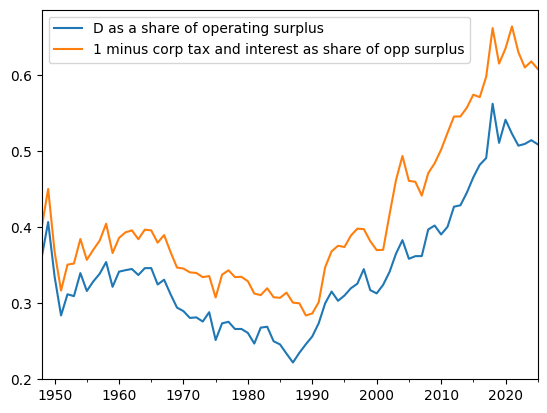

In [7]:
#nonfinancial corporate business, from the Fed's Financial Accounts (via FRED)
corp_opp_surp_df = fetch_fred_series({'NCBDPAA027N':'dividends',
                                      'NCBOSNA027N': 'opp_surp',
                                      'NCBTIWA027N':'corp_tax',
                                      'NCBIPAA027N':'interest',
                                      'NCBPIRA027N':'prop_rec','NCBSECA027N':'net_savings','NCBCTPA027N':'cap_trans'},start_date='1948')
corp_opp_surp_df['net_savings'] = corp_opp_surp_df['net_savings'] + corp_opp_surp_df['cap_trans']
pct_composition = corp_opp_surp_df.div(corp_opp_surp_df.opp_surp+corp_opp_surp_df.prop_rec - corp_opp_surp_df.net_savings, axis=0)
ax = pct_composition.dividends.plot(label='D as a share of operating surplus',legend=True)
(1-(pct_composition.interest + pct_composition.corp_tax)).plot(ax=ax, label='1 minus corp tax and interest as share of opp surplus',legend=True)
plt.show()

In [8]:
#quarterly S&P 500 dividend yield (D/P) from the Shiller data, reinvested every quarter to build total return indexes
dividend_yield = snp.D.resample('QS').first()/snp.P.resample('QS').first()

TRI = ((1+dividend_yield/4).cumprod()*raw_capitalized).dropna() #capitalized profit, with dividends reinvested
snp_TRI = ((1+dividend_yield/4).cumprod()*snp.P.resample('QS').first()).dropna() #S&P 500 total return index

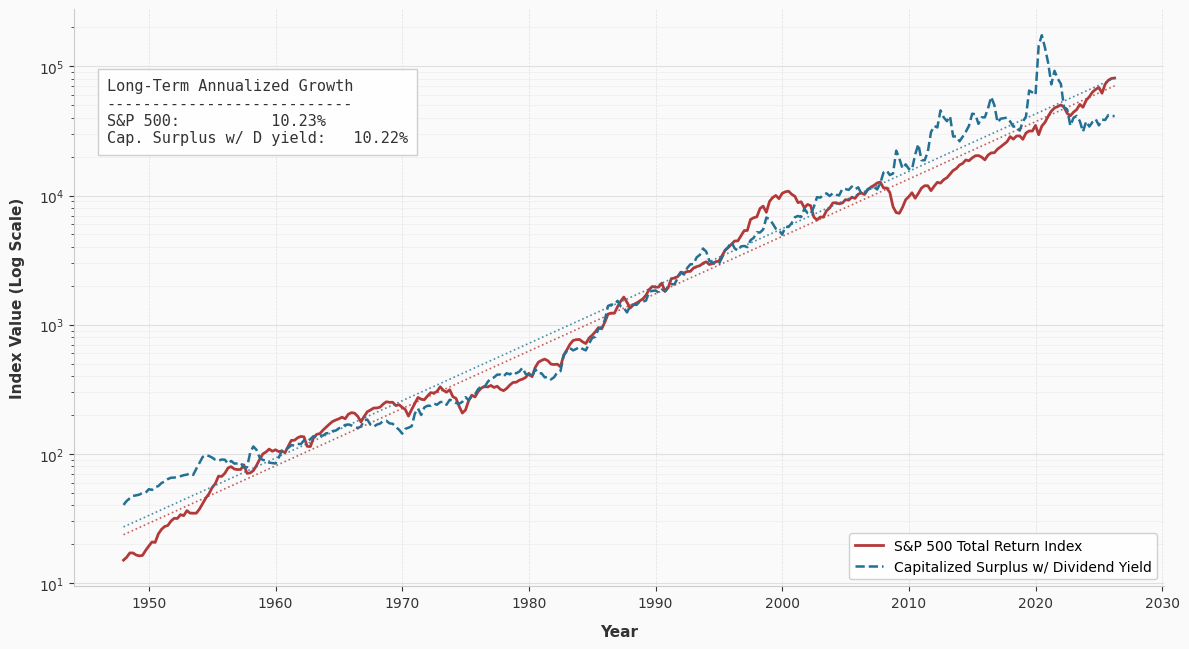

In [9]:
#same comparison as above, but for total return: S&P 500 total return vs capitalized profit with the dividend yield reinvested
#(variables get a _tri suffix so they don't overwrite the price comparison's)
common_dates_tri = TRI.index.intersection(snp_TRI.index)
TRI_aligned = TRI.loc[common_dates_tri]
snp_TRI_aligned = snp_TRI.loc[common_dates_tri]

# 2. Apply historical 1948-1980 scaling
closed_phase_tri = common_dates_tri[common_dates_tri < '1981-01-01']
scaling_factor_tri = snp_TRI_aligned.loc[closed_phase_tri].mean() / TRI_aligned.loc[closed_phase_tri].mean()
TRI_scaled = TRI_aligned * scaling_factor_tri

# 3. Prepare variables for log linear regression
t_tri = (common_dates_tri - common_dates_tri[0]).days / 365.25

# 4. Compute OLS Linear Regression Slopes
slope_snp_tri, intercept_snp_tri, _, _, _ = linregress(t_tri, np.log(snp_TRI_aligned))
slope_cap_tri, intercept_cap_tri, _, _, _ = linregress(t_tri, np.log(TRI_scaled))

growth_rate_snp_tri = slope_snp_tri * 100
growth_rate_cap_tri = slope_cap_tri * 100

# 5. Visualization
fig, ax = plt.subplots(figsize=(12, 7.5), facecolor='#FAFAFA')
ax.set_facecolor('#FAFAFA')

ax.plot(common_dates_tri, snp_TRI_aligned, label='S&P 500 Total Return Index', color=color_P, linewidth=2)
ax.plot(common_dates_tri, TRI_scaled, label='Capitalized Surplus w/ Dividend Yield', color=color_sM, linewidth=1.8, linestyle='--')

# Plot OLS Trendlines
ax.plot(common_dates_tri, np.exp(intercept_snp_tri + slope_snp_tri * t_tri), color=color_P, linestyle=':', linewidth=1.2, alpha=0.8)
ax.plot(common_dates_tri, np.exp(intercept_cap_tri + slope_cap_tri * t_tri), color=color_sM, linestyle=':', linewidth=1.2, alpha=0.8)

# Format Axes and Grid
ax.set_yscale('log')
ax.grid(True, which="major", axis='y', color='#E0E0E0', linestyle='-', linewidth=0.8)
ax.grid(True, which="minor", axis='y', color='#EBEBEB', linestyle='-', linewidth=0.4)
ax.grid(True, which="major", axis='x', color='#E0E0E0', linestyle='--', linewidth=0.5)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#CCCCCC')
ax.spines['bottom'].set_color('#CCCCCC')
ax.tick_params(colors=color_text, which='both')

ax.set_ylabel('Index Value (Log Scale)', fontsize=11, color=color_text, weight='bold', labelpad=10)
ax.set_xlabel('Year', fontsize=11, color=color_text, weight='bold', labelpad=10)

text_str = (
    f"Long-Term Annualized Growth\n"
    f"---------------------------\n"
    f"S&P 500:          {growth_rate_snp_tri:.2f}%\n"
    f"Cap. Surplus w/ D yield:   {growth_rate_cap_tri:.2f}%"
)
props = dict(boxstyle='square,pad=0.6', facecolor='white', edgecolor='#CCCCCC', alpha=0.95)
ax.text(0.03, 0.88, text_str, transform=ax.transAxes, fontsize=11,
        verticalalignment='top', bbox=props, color=color_text, family='monospace')

ax.legend(fontsize=10, loc='lower right', frameon=True, facecolor='white', edgecolor='#CCCCCC', framealpha=0.9)

plt.tight_layout()
plt.subplots_adjust(top=0.86)
plt.show()

### Stock Price Projection Scenarios

/tmp/ipykernel_1000/523763647.py:114: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


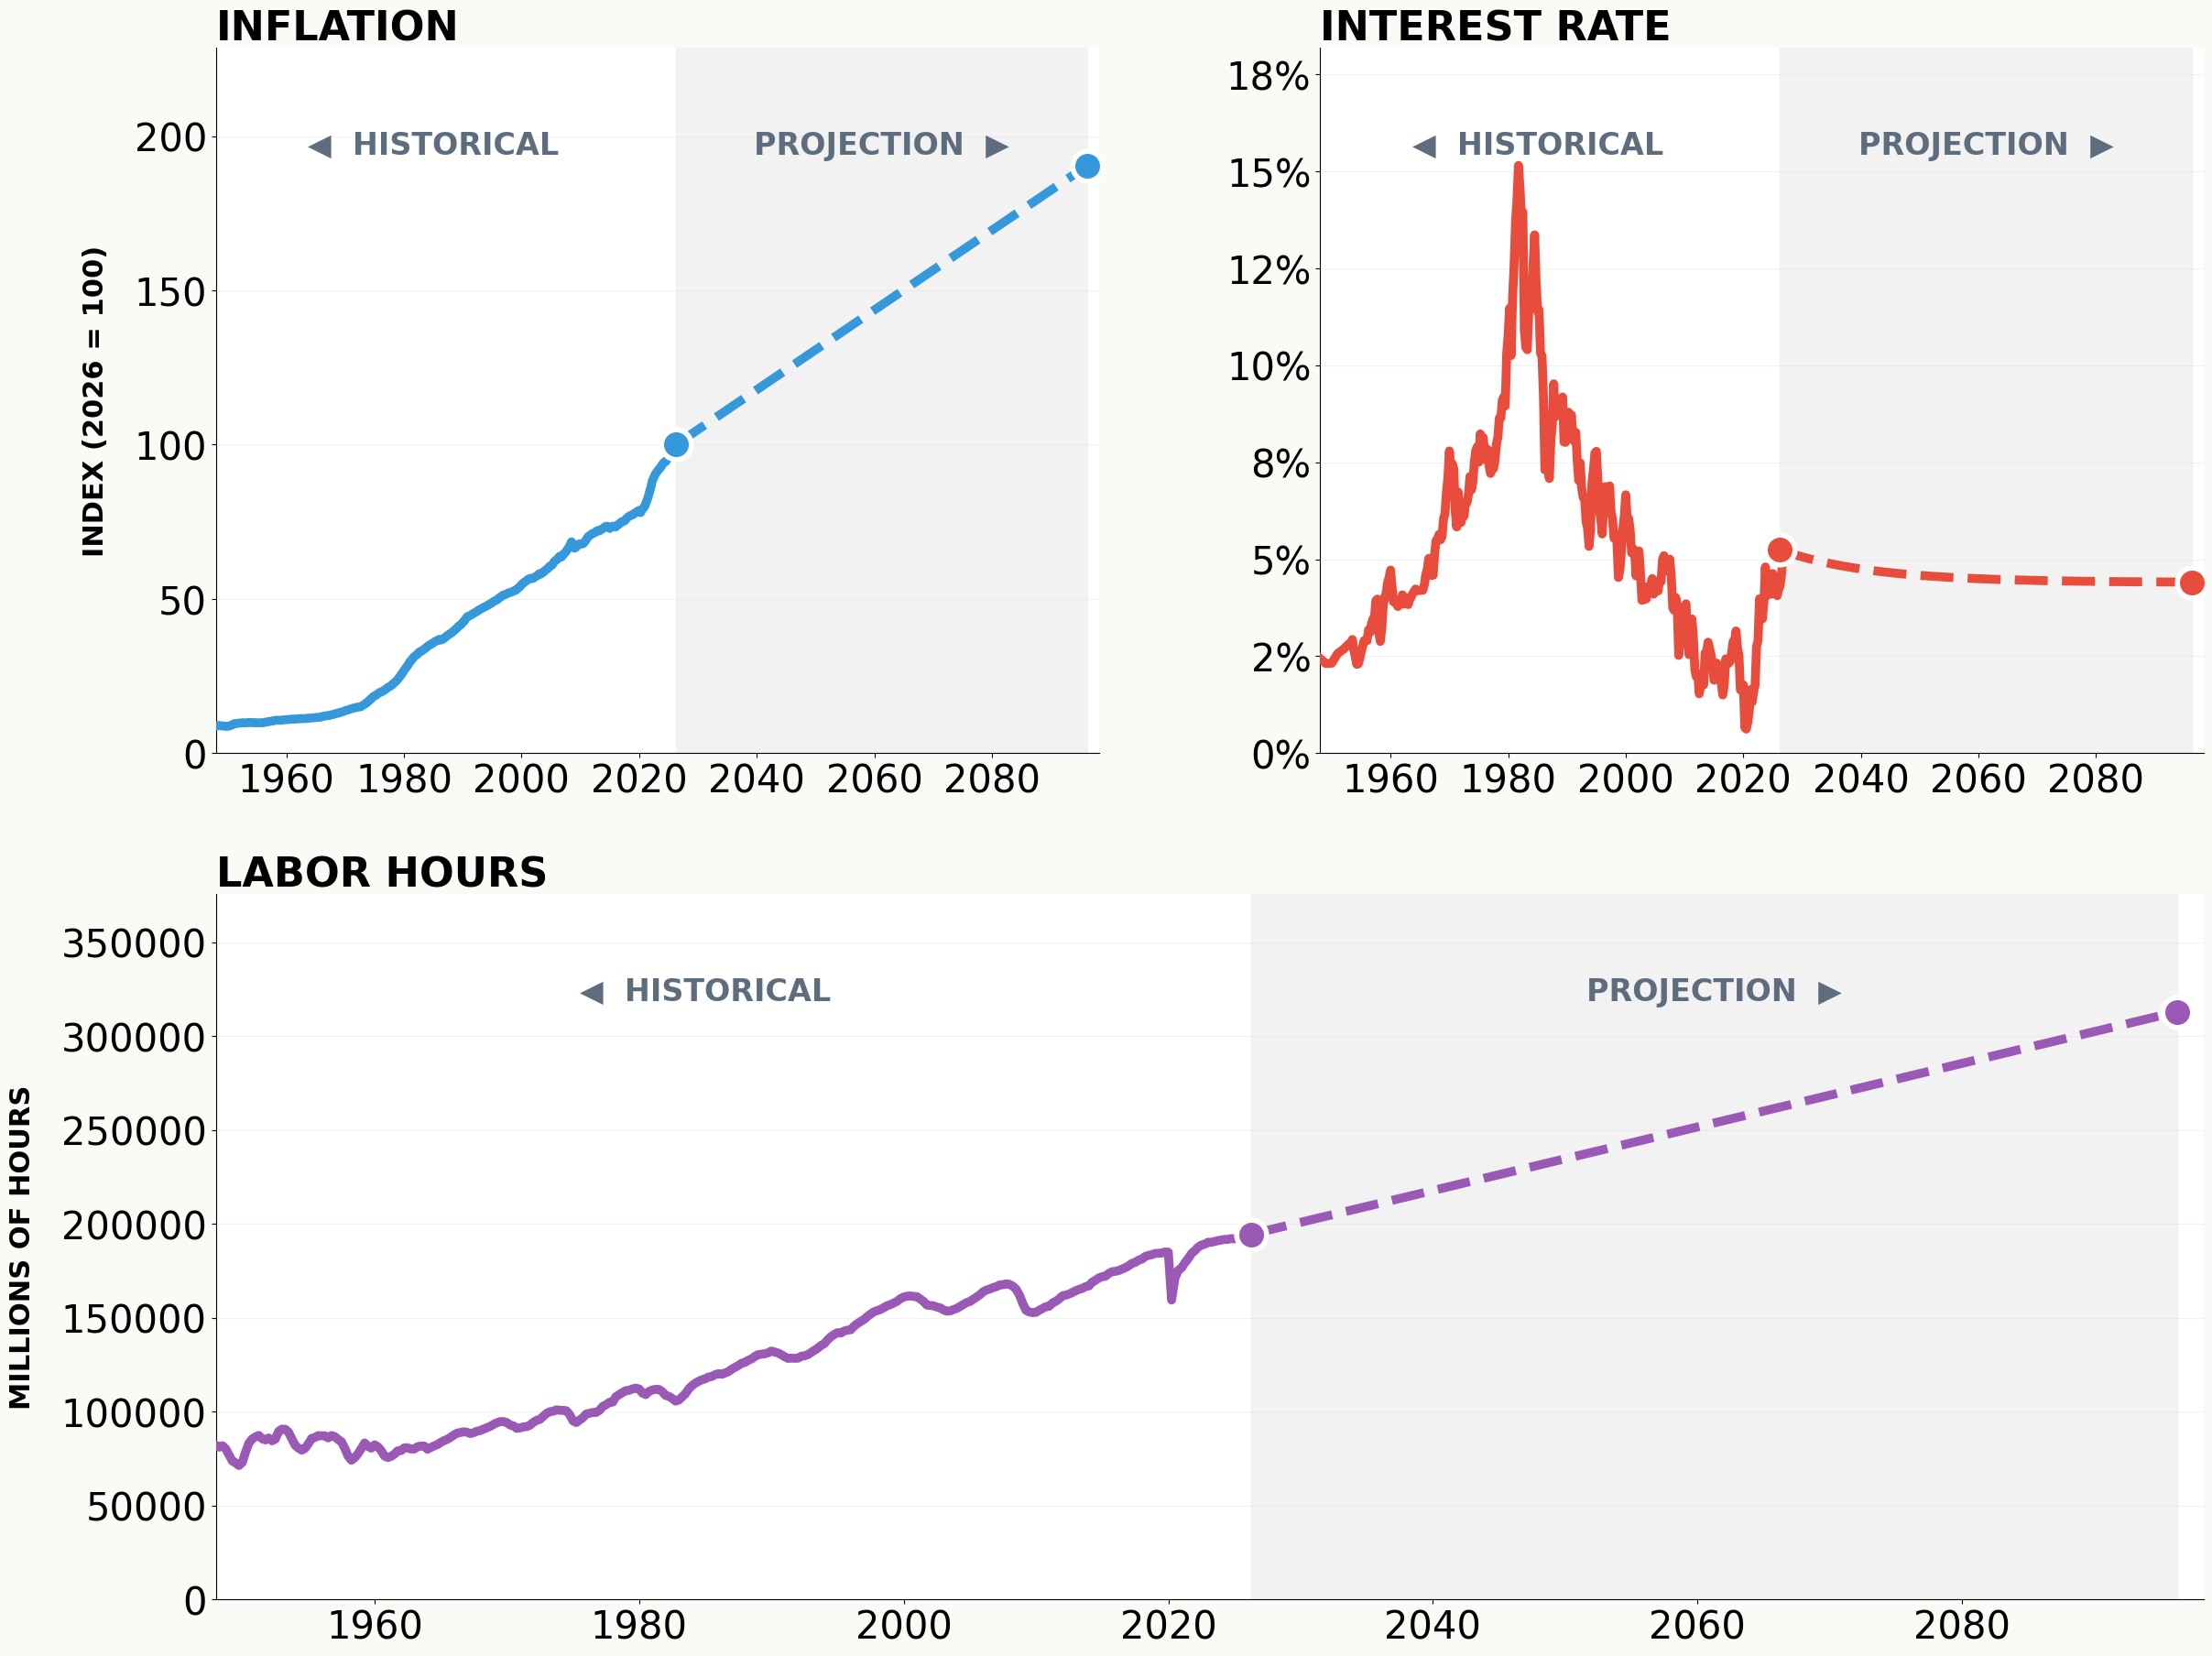

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.dates as mdates

# ── 1. Data Preparation ━━━━━━━━━━━━━━━━━━━━━━━━
PROJECTION_YEARS = 40+30 #a 40 year career then 30 years of retirement

start_date = final_df.index[0]
target_date = last_hist_date + pd.DateOffset(years=PROJECTION_YEARS)

projection_index = pd.date_range(
    start=last_hist_date + pd.DateOffset(months=3),
    end=target_date,
    freq='QS'
)

inflation = 100 / final_df['cpi_deflator'] #price index, latest quarter = 100
labor_hours = final_df['pn_hours_millions']
interest_rate = rate_quarterly
days_ahead = (projection_index - last_hist_date).days.values #days from the latest data to each projected quarter

# Projections
# Inflation: linear slope, 1980 first obs → 2020 last obs
inf_start = inflation[inflation.index.year == 1980]
inf_end   = inflation[inflation.index.year == 2020]
inf_days  = (inf_end.index[-1] - inf_start.index[0]).days
slope_inf = (inf_end.iloc[-1] - inf_start.iloc[0]) / inf_days
inf_proj = pd.Series(inflation.iloc[-1] + slope_inf * days_ahead, index=projection_index)

# Interest rate: converges to CBO's long-run 4.4% at the exponential rate it fell over 1980 → 2020
ir_start = interest_rate[interest_rate.index.year == 1980]
ir_end   = interest_rate[interest_rate.index.year == 2020]
ir_days  = (ir_end.index[-1] - ir_start.index[0]).days
k_ir     = np.log(ir_end.iloc[-1] / ir_start.iloc[0]) / ir_days
#https://www.cbo.gov/publication/62105
ir_proj = pd.Series((interest_rate.iloc[-1] - 4.4) * np.exp(k_ir * days_ahead) + 4.4, index=projection_index)

# Labor hours: linear trend since 1960
lh_start = labor_hours[labor_hours.index.year >= 1960]
slope_lh = (labor_hours.iloc[-1] - lh_start.iloc[0]) / (labor_hours.index[-1] - lh_start.index[0]).days
lh_proj = pd.Series(labor_hours.iloc[-1] + slope_lh * days_ahead, index=projection_index)

# ── 2. Thematic Settings ━━━━━━━━━━━━━━━━━
BG_HIST = '#FFFFFF'     # Historical area
BG_PROJ = '#F2F2F2'     # Projection area
GRID_COLOR = '#E0E0E0'
TEXT_COLOR = '#1A1A1A'
LABEL_COLOR = '#5D6D7E'

PALETTE = {
    'Inflation': '#3498DB',
    'Interest Rate': '#E74C3C',
    'Labor Hours': '#9B59B6'
}

# ── 3. Plotting ━━━━━━━━━━━━━━━━━
fig = plt.figure(figsize=(28, 22), facecolor='#FAFAF7')
# Triangle formation: 2x2 grid, bottom plot spans both columns
gs = fig.add_gridspec(2, 2, hspace=0.2, wspace=0.25)

axes = [
    fig.add_subplot(gs[0, 0]), # Top Left
    fig.add_subplot(gs[0, 1]), # Top Right
    fig.add_subplot(gs[1, :])  # Bottom Wide
]

datasets = [
    (inflation, inf_proj, 'Inflation', f'INDEX ({last_hist_date.year} = 100)'),
    (interest_rate, ir_proj, 'Interest Rate', ''),
    (labor_hours, lh_proj, 'Labor Hours', 'MILLIONS OF HOURS')
]

for i, (ax, (hist, proj, title, ylabel)) in enumerate(zip(axes, datasets)):
    color = PALETTE[title]
    combined_series = pd.concat([hist, proj]).sort_index()
    y_lim_max = combined_series.max() * 1.2

    # ── Background Shading ──
    ax.axvspan(start_date, last_hist_date, color=BG_HIST, zorder=0)
    ax.axvspan(last_hist_date, target_date, color=BG_PROJ, zorder=0)

    # Era Labels
    ax.text(pd.to_datetime('1985-01-01'), y_lim_max * 0.85, '◀  HISTORICAL',
            fontsize=24, fontweight='black', color=LABEL_COLOR, ha='center')
    ax.text(last_hist_date + (target_date - last_hist_date) / 2, y_lim_max * 0.85, 'PROJECTION  ▶',
        fontsize=24, fontweight='black', color=LABEL_COLOR, ha='center')

    # Lines
    ax.plot(hist.index, hist, color=color, lw=7, zorder=3)
    ax.plot(proj.index, proj, color=color, lw=7, linestyle='--', zorder=3)

    # Two dots: the latest data and the end of the projection
    ax.scatter(last_hist_date, hist.iloc[-1], color=color, edgecolor='white', s=550, zorder=6, lw=4)
    ax.scatter(target_date, proj.iloc[-1], color=color, edgecolor='white', s=550, zorder=6, lw=4)

    # Formatting
    ax.set_ylim(0, y_lim_max)
    ax.set_xlim(start_date, target_date + pd.DateOffset(years=2))
    ax.xaxis.set_major_locator(mdates.YearLocator(20))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

    if title == 'Interest Rate':
        ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=100, decimals=0))

    ax.set_ylabel(ylabel, fontsize=22, fontweight='black', labelpad=20)
    ax.set_title(title.upper(), loc='left', fontsize=32, fontweight='black', pad=-10)

    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='y', color=GRID_COLOR, linestyle='-', alpha=0.4, zorder=1)
    ax.tick_params(axis='both', labelsize=30)

plt.tight_layout()
plt.show()

In [11]:
inflation_full_proj = pd.concat([inflation, inf_proj])
#rate_quarterly runs a couple quarters past last_hist_date, cut it so it doesn't overlap the projection
interest_rate_full_proj = pd.concat([interest_rate.loc[:last_hist_date], ir_proj])
labor_hours_full_proj = pd.concat([labor_hours, lh_proj])

In [12]:
from scipy.stats import linregress

SCENARIO_NAMES = {'widens': 'Gap widens', 'holds': 'Gap holds', 'closes': 'Gap closes'}

# "productivity" continues its linear trend since 1948
B_trend = (B_hist.iloc[-1] - B_hist.iloc[0]) / (B_hist.index[-1] - B_hist.index[0]).days #real $/hr per day
B_proj = pd.Series(B_hist.iloc[-1] + B_trend * days_ahead, index=projection_index)

# the gap's average pace since 1948
sigma_1948_slice = sigma[sigma.index.year == 1948]
sigma_1948 = sigma_1948_slice.iloc[0] if not sigma_1948_slice.empty else sigma.iloc[0]
sigma_end = sigma.iloc[-1]
sigma_trend = (sigma_end - sigma_1948) / (sigma.index[-1] - sigma.index[0]).days #real $/hr per day

sigma_proj = {
    'widens': pd.Series(sigma_end + sigma_trend * days_ahead, index=projection_index), #keeps growing at its historical pace
    'holds': pd.Series(sigma_end, index=projection_index), #stays at today's size
    'closes': pd.Series(sigma_end - sigma_trend * days_ahead, index=projection_index).clip(lower=sigma_1948), #shrinks back to its 1948 size, then stays there
}

def capitalized_total_return(sigma_path):
    #profit = gap x hours, in nominal $, capitalized at the interest rate (P = D/r), with the yield (D/P = r) reinvested every quarter
    value = sigma_path * labor_hours_full_proj * 1e6 * (inflation_full_proj/100) / (interest_rate_full_proj/100) * (1 + interest_rate_full_proj/400).cumprod()
    # Remove duplicate labels created by overlapping historical/projection data before setting frequency
    return value[~value.index.duplicated(keep='last')].asfreq('QS-JAN')

sigma_scenarios = {k: pd.concat([sigma, proj]) for k, proj in sigma_proj.items()}
stock_scenarios = {k: capitalized_total_return(path).rename(SCENARIO_NAMES[k]) for k, path in sigma_scenarios.items()}
wage_scenarios = {k: pd.concat([w_hist, B_proj - proj]) for k, proj in sigma_proj.items()} #pay = "productivity" minus the gap

def calculate_cagr(series, start_year=None):
    #compound annual growth from the first quarter of start_year (default: the year of the latest data) to the end of the series
    start_date = pd.to_datetime(f'{start_year or last_hist_date.year}-01-01')
    sub_series = series[series.index >= start_date]
    if len(sub_series) < 2:
        return 0.0
    v_start = sub_series.iloc[0]
    v_end = sub_series.iloc[-1]

    # Calculate exact number of years based on datetime difference
    days = (sub_series.index[-1] - sub_series.index[0]).days
    if days <= 0:
        return 0.0
    years = days / 365.25

    cagr = (v_end / v_start) ** (1 / years) - 1
    return cagr * 100

def calculate_trend_growth(series, start_year=None):
    # Slope of a log-linear OLS fit x 100, the same method as the 'Long-Term Annualized Growth' charts
    if start_year is not None:
        series = series[series.index >= pd.to_datetime(f'{start_year}-01-01')]
    series = series.dropna()
    if len(series) < 2:
        return 0.0
    t = (series.index - series.index[0]).days / 365.25
    return linregress(t, np.log(series)).slope * 100

#### 3 scenario plot

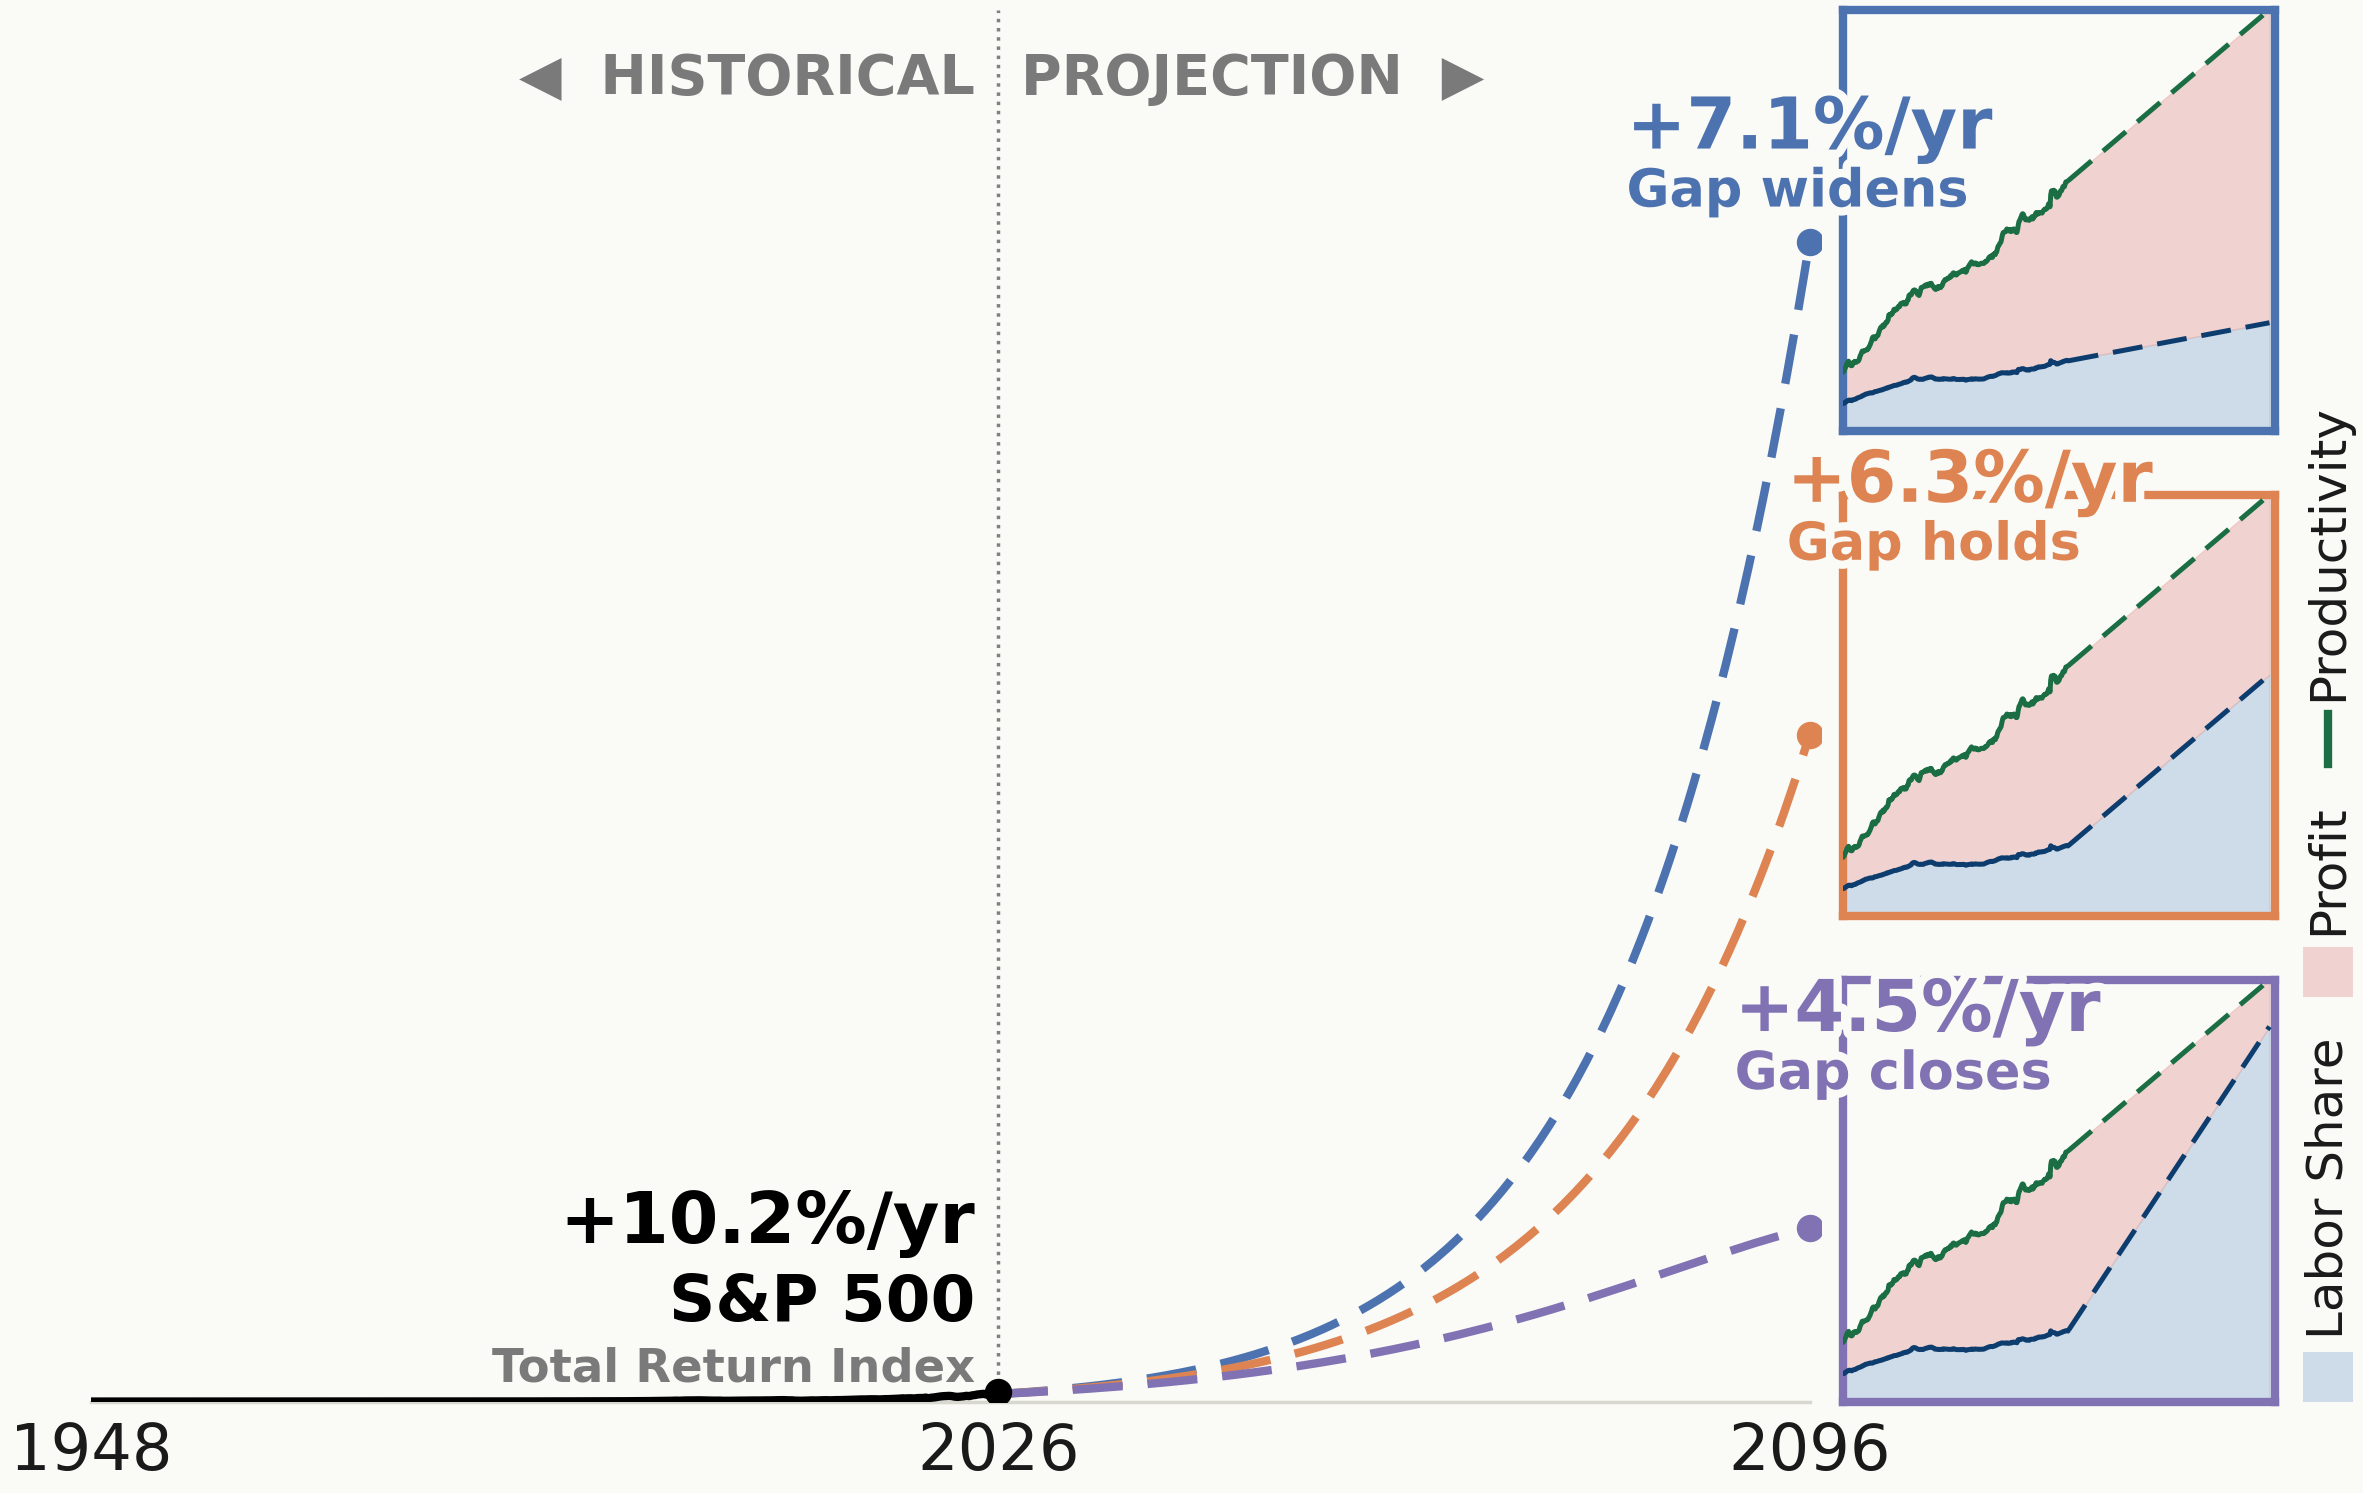

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.patheffects as pe
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from matplotlib.transforms import Bbox

# ── 1. Color Palette & Mobile Styling ─────────────────────────────────────────
# The figure is 24in wide; shown ~375px wide on a phone, 1px ≈ 4.6pt,
# so 46pt tick labels land at ~10px and the growth rates at ~13px.
# matplotlib's default font
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans']

BG_COLOR   = '#FAFAF7'
PROD_COLOR = '#1B6E44'
WAGE_COLOR = '#0D3D6E'
SURP_FILL  = '#E8B4B0'
WAGE_FILL  = '#A8C4DC'
GRID_COLOR = '#D8D8D0'
TEXT_COLOR = '#1A1A1A'
LABEL_COLOR = '#7A7A7A'

LW = 6.0
PANEL_LW = LW * 0.6      # lighter lines suit the small side panels
AXIS_LW = 2.5
TICK_FONT_SIZE = 46
LABEL_FONT_SIZE = 44     # scenario names
LEGEND_FONT_SIZE = 36    # rotated legend, sized to fit the height of panels B, C, D
RATE_FONT_SIZE = 60      # growth-rate read-outs
HEADER_FONT_SIZE = 40    # HISTORICAL / PROJECTION
DOT_SIZE = 350

# ── 2. Scenario Data ──────────────────────────────────────────────────────────
proj_mask = stock_scenarios['widens'].index >= last_hist_date

# Historical line: actual S&P 500 total return index (Shiller data, dividends reinvested)
stock_hist = snp_TRI.loc[start_date:last_hist_date]
# Rebase the model projections so every scenario starts from the actual S&P level at last_hist_date
rebase = stock_hist.iloc[-1] / stock_scenarios['widens'].loc[last_hist_date]
stock_proj = {k: s[proj_mask] * rebase for k, s in stock_scenarios.items()}

# Gap widens blue, Gap holds orange, Gap closes purple; no green, so green only ever means productivity
SCENARIO_COLORS = {'widens': '#4C72B0', 'holds': '#DD8452', 'closes': '#8172B3'}

# Ordered top to bottom as the lines end: (S&P projection, name, color, gap projection, panel)
scenario_lines = [(stock_proj[k], SCENARIO_NAMES[k], SCENARIO_COLORS[k], sigma_proj[k], panel)
                  for k, panel in [('widens', 'B'), ('holds', 'C'), ('closes', 'D')]]

B_full = pd.concat([B_hist, B_proj])
hist_growth = calculate_trend_growth(stock_hist)

def to_display(ax, series):
    series = series.dropna()
    return ax.transData.transform(np.column_stack([mdates.date2num(series.index), series.values]))

def densify(pts, step=4.0):
    # Fill in a display-space polyline so consecutive points are at most `step` pixels apart
    seg = np.diff(pts, axis=0)
    counts = np.maximum(1, (np.hypot(seg[:, 0], seg[:, 1]) // step).astype(int))
    pieces = [pts[:1]] + [p + np.outer(np.arange(1, k + 1) / k, d) for p, d, k in zip(pts[:-1], seg, counts)]
    return np.vstack(pieces)


def plot_scenarios():
    # ── 3. Mosaic Layout ──────────────────────────────────────────────────────
    layout = """
    AB
    AC
    AD
    """
    fig, axes = plt.subplot_mosaic(layout, figsize=(24, 16), facecolor=BG_COLOR, width_ratios=[4, 1])

    for ax in axes.values():
        ax.set_facecolor(BG_COLOR)
        ax.spines[['top', 'right']].set_visible(False)
        ax.spines['bottom'].set_color(GRID_COLOR)
        ax.spines['bottom'].set_linewidth(AXIS_LW)
        ax.tick_params(axis='x', labelsize=TICK_FONT_SIZE, labelcolor=TEXT_COLOR, length=0, pad=14)

    # ── 4. Plot A: Stock Price Scenarios ──────────────────────────────────────
    ax_A = axes['A']
    ax_A.plot(stock_hist.index, stock_hist, color='black', lw=LW, zorder=3, solid_capstyle='round')
    for series, _, color, _, _ in scenario_lines:
        ax_A.plot(series.index, series, lw=LW, linestyle=(0, (6, 3)), color=color, zorder=3)

    y_max_A = max(series.max() for series, _, _, _, _ in scenario_lines)
    ax_A.set_ylim(0, y_max_A * 1.2)
    # No y-axis: the growth rates carry the comparison
    ax_A.yaxis.set_visible(False)
    ax_A.spines['left'].set_visible(False)

    # Lines run right up to panels B, C, D; just enough room past target_date for the end dots
    ax_A.set_xlim(start_date, target_date + pd.DateOffset(years=1))
    ax_A.spines['bottom'].set_bounds(mdates.date2num(start_date), mdates.date2num(target_date))
    # Three anchors on the time axis: start of the data, today, end of the projection
    tick_dates = [stock_hist.index[0], last_hist_date, target_date]
    ax_A.set_xticks(tick_dates)
    ax_A.set_xticklabels([str(d.year) for d in tick_dates])

    ax_A.vlines(last_hist_date, ymin=0, ymax=y_max_A * 1.2, linestyles='dotted', color='grey', lw=AXIS_LW)
    header = [ax_A.text(last_hist_date - pd.DateOffset(years=2), 0.97, '◀  HISTORICAL', transform=ax_A.get_xaxis_transform(),
                        fontsize=HEADER_FONT_SIZE, fontweight='black', color=LABEL_COLOR, ha='right', va='top'),
              ax_A.text(last_hist_date + pd.DateOffset(years=2), 0.97, 'PROJECTION  ▶', transform=ax_A.get_xaxis_transform(),
                        fontsize=HEADER_FONT_SIZE, fontweight='black', color=LABEL_COLOR, ha='left', va='top')]

    ax_A.scatter([last_hist_date], [stock_hist.iloc[-1]], color='black', s=DOT_SIZE, zorder=5)
    for series, _, color, _, _ in scenario_lines:
        ax_A.scatter([series.index[-1]], [series.iloc[-1]], color=color, s=DOT_SIZE, zorder=5)

    # ── 5. Plots B, C, D: Productivity-Pay Gap Scenarios ──────────────────────
    for _, _, color, sig_proj, ax_key in scenario_lines:
        ax = axes[ax_key]
        w_proj = B_proj - sig_proj
        w_full = pd.concat([w_hist, w_proj])
        y_max = B_proj.max()

        ax.fill_between(B_full.index, 0, w_full, color=WAGE_FILL, alpha=0.55, zorder=1)
        ax.fill_between(B_full.index, w_full, B_full, color=SURP_FILL, alpha=0.55, zorder=1)
        ax.plot(B_hist.index, B_hist, color=PROD_COLOR, lw=PANEL_LW, zorder=3, solid_capstyle='round')
        ax.plot(w_hist.index, w_hist, color=WAGE_COLOR, lw=PANEL_LW, zorder=3, solid_capstyle='round')
        ax.plot(B_proj.index, B_proj, color=PROD_COLOR, lw=PANEL_LW, linestyle=(0, (6, 3)), zorder=3)
        ax.plot(w_proj.index, w_proj, color=WAGE_COLOR, lw=PANEL_LW, linestyle=(0, (6, 3)), zorder=3)

        ax.set_ylim(0, y_max)
        ax.set_xlim(start_date, target_date + pd.DateOffset(years=2))
        ax.set_xticks([])
        ax.set_yticks([])
        # A border in the scenario's color ties the panel to its line in Plot A
        for spine in ax.spines.values():
            spine.set(visible=True, color=color, linewidth=LW)

    # No gap between Plot A and panels B, C, D; a narrow right margin holds the rotated legend
    fig.subplots_adjust(top=0.95, bottom=0.08, left=0.03, right=0.94, wspace=0.02, hspace=0.15)

    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()

    # ── 6. Legend for Plots B, C, D (rotated, reading up the right edge) ──────
    # Entries stack bottom to top in the same order as the fills in the panels
    legend_entries = [('Labor Share', WAGE_FILL), ('Profit', SURP_FILL), ('Productivity', PROD_COLOR)]
    legend_x = axes['B'].get_position().x1 + 0.022
    handle_w, handle_h = 0.5 / 24, 0.5 / 16    # 0.5in square, in figure fractions
    handle_pad, entry_gap = 0.008, 0.025

    legend_texts = [fig.text(legend_x, 0, name, rotation=90, fontsize=LEGEND_FONT_SIZE, color=TEXT_COLOR,
                             ha='center', va='bottom') for name, _ in legend_entries]
    text_heights = [t.get_window_extent(renderer).transformed(fig.transFigure.inverted()).height for t in legend_texts]

    y = axes['D'].get_position().y0    # first handle sits flush with the panels' bottom axis
    for (name, color), text, text_h in zip(legend_entries, legend_texts, text_heights):
        if name == 'Productivity':
            fig.add_artist(Line2D([legend_x, legend_x], [y, y + handle_h], color=color, lw=LW,
                                  transform=fig.transFigure))
        else:
            fig.add_artist(Rectangle((legend_x - handle_w / 2, y), handle_w, handle_h, facecolor=color,
                                     alpha=0.55, edgecolor='none', transform=fig.transFigure))
        text.set_y(y + handle_h + handle_pad)
        y += handle_h + handle_pad + text_h + entry_gap

    # ── 7. Scenario labels ────────────────────────────────────────────────────
    # Each growth rate + name block sits just above or below its end dot and pushes into the white
    # corner of its own panel, clear of every line. All three shrink together until each one fits.
    ax_A.set_zorder(1)    # labels may spill over the panels
    to_data = ax_A.transData.inverted()
    pad = 12              # display pixels
    stroke = [pe.withStroke(linewidth=12, foreground=BG_COLOR)]    # clean break where text crosses a border

    a_lines = np.vstack([densify(to_display(ax_A, stock_hist))]
                        + [densify(to_display(ax_A, series)) for series, _, _, _, _ in scenario_lines])
    panel_lines = {key: densify(to_display(axes[key], B_full)) for key in 'BCD'}
    panel_boxes = {key: axes[key].get_window_extent(renderer) for key in 'BCD'}
    top_limit = fig.bbox.y1 - pad
    bottom_limit = panel_boxes['D'].y0 + pad
    right_limit = panel_boxes['B'].x1    # stay clear of the legend

    def box_is_clear(x0, y0, x1, y1, placed, own_key):
        if x1 > right_limit or y1 > top_limit or y0 < bottom_limit:
            return False
        hit = ((a_lines[:, 0] > x0 - pad) & (a_lines[:, 0] < x1 + pad)
               & (a_lines[:, 1] > y0 - pad) & (a_lines[:, 1] < y1 + pad))
        if hit.any():
            return False
        if any(x0 < b.x1 and b.x0 < x1 and y0 < b.y1 and b.y0 < y1 for b in placed):
            return False
        # A block may spill only into its own panel, and there only into the white above the productivity line
        for key, box in panel_boxes.items():
            if x1 <= box.x0 - pad or x0 >= box.x1 + pad or y1 <= box.y0 - pad or y0 >= box.y1 + pad:
                continue
            if key != own_key:
                return False
            under = panel_lines[key]
            under = under[(under[:, 0] >= x0 - pad) & (under[:, 0] <= x1 + pad)]
            if (under[:, 1] >= y0 - pad).any():
                return False
        return True

    def place_block(rate, label, dot, placed, own_key):
        # Puts the block as close to its dot as it fits; returns its display Bbox, or None
        rate_box = rate.get_window_extent(renderer)
        label_box = label.get_window_extent(renderer)
        w = max(rate_box.width, label_box.width)
        h = rate_box.height + 4 + label_box.height
        for step in range(0, int(3 * h), 4):
            for top in (dot[1] + pad + h + step, dot[1] - pad - step):    # above the dot, then below
                y0 = top - h
                band = a_lines[(a_lines[:, 1] > y0 - pad) & (a_lines[:, 1] < top + pad) & (a_lines[:, 0] < dot[0] + pad)]
                x0 = dot[0] - w / 2
                if len(band):
                    x0 = max(x0, band[:, 0].max() + pad)
                if box_is_clear(x0, y0, x0 + w, top, placed, own_key):
                    rate.xy = tuple(to_data.transform((x0, top)))
                    label.xy = tuple(to_data.transform((x0, top - rate_box.height - 4)))
                    return Bbox.from_extents(x0, y0, x0 + w, top)
        return None

    # annotation_clip=False: blocks may be anchored over the panels, and a clipped annotation measures as 1x1 px
    end_labels = []
    for series, name, color, _, _ in scenario_lines:
        end_x, end_y = series.index[-1], series.iloc[-1]
        rate = ax_A.annotate(f"{calculate_trend_growth(series, start_year=last_hist_date.year):+.1f}%/yr", xy=(end_x, end_y),
                             xytext=(0, 0), textcoords='offset points', color=color, annotation_clip=False,
                             fontweight='bold', ha='left', va='top', path_effects=stroke)
        label = ax_A.annotate(name, xy=(end_x, end_y), xytext=(0, 0), textcoords='offset points', color=color,
                              annotation_clip=False, fontweight='bold', ha='left', va='top', path_effects=stroke)
        end_labels.append((rate, label))
    dots = [to_display(ax_A, series)[-1] for series, _, _, _, _ in scenario_lines]

    scale = 1.0
    while True:
        for rate, label in end_labels:
            rate.set_fontsize(RATE_FONT_SIZE * scale)
            label.set_fontsize(LABEL_FONT_SIZE * scale)
        placed = [text.get_window_extent(renderer) for text in header]
        for (rate, label), dot, (_, _, _, _, ax_key) in zip(end_labels, dots, scenario_lines):
            box = place_block(rate, label, dot, placed, ax_key)
            if box is None:
                break
            placed.append(box)
        else:
            break
        scale *= 0.95
        if scale < 0.4:
            raise RuntimeError('Scenario labels do not fit beside their end dots')

    # S&P 500 label just above and left of today's dot, at the same scale as the scenario labels
    sp_anchor = (last_hist_date - pd.DateOffset(years=2), stock_hist.iloc[-1] * 1.15)
    sub_size, name_size, rate_size = TICK_FONT_SIZE * 0.85 * scale, (LABEL_FONT_SIZE + 10) * scale, RATE_FONT_SIZE * scale
    ax_A.annotate('Total Return Index', xy=sp_anchor, color=LABEL_COLOR,
                  fontsize=sub_size, fontweight='bold', ha='right', va='bottom')
    ax_A.annotate('S&P 500', xy=sp_anchor, xytext=(0, sub_size + 8), textcoords='offset points',
                  color='black', fontsize=name_size, fontweight='bold', ha='right', va='bottom')
    ax_A.annotate(f"{hist_growth:+.1f}%/yr", xy=sp_anchor,
                  xytext=(0, sub_size + 8 + name_size + 8), textcoords='offset points',
                  color='black', fontsize=rate_size, fontweight='bold', ha='right', va='bottom')

    plt.show()


plot_scenarios()

In [14]:
widens_price_only = sigma_scenarios['widens'] * labor_hours_full_proj * 1e6 * (inflation_full_proj/100) / (interest_rate_full_proj/100)
price_only_cagr = calculate_cagr(widens_price_only)
print(f'Gap widens, stock price only (no dividends): {price_only_cagr:.1f}%/yr')

one_pct_rate = pd.Series(1.0, index=inflation_full_proj.index)
one_pct_cagr = calculate_cagr(sigma_scenarios['widens'] * labor_hours_full_proj * 1e6 * (inflation_full_proj/100) / (one_pct_rate/100) * (1 + one_pct_rate/400).cumprod())
print(f'Gap widens, total return if rates stayed at 1%: {one_pct_cagr:.1f}%/yr')

Gap widens, stock price only (no dividends): 2.4%/yr
Gap widens, total return if rates stayed at 1%: 3.5%/yr


### Retirement breakeven
Spending is held the same across scenarios (what it would be in Gap widens at a given saving rate), so any extra pay in the higher-wage scenarios is saved.

In [15]:
import numpy as np
import pandas as pd

# ==========================================
# 1. CONFIGURATION & CONSTANTS
# ==========================================
HOURS_PER_YEAR = 2080
CAREER_YEARS = 40
RETIRE_YEARS = 30
RETIREMENT_QUARTERS = RETIRE_YEARS * 4

RETIRE_AGE = 65

savings_rates = np.arange(0, 1, 0.01).round(2)
today = last_hist_date
ages = [25, 35, 45, 55]

#scenario -> (capitalized total return, pay per hour), Gap widens is the baseline everything is compared to
scenarios = {k: (stock_scenarios[k], wage_scenarios[k]) for k in ['widens', 'holds', 'closes']}


# ==========================================
# 2. HELPER FUNCTIONS
# ==========================================

def market_series(stock_scenario):
    """Combines historical S&P total return data up to today with scenario projections."""
    future_projection = (
        stock_scenario.loc[today:]
        * snp_TRI.loc[today]
        / stock_scenario.loc[today]
    )
    historical_series = snp_TRI.loc[:today - pd.DateOffset(months=3)]
    return pd.concat([historical_series, future_projection])


def retirement_cost(real_stock_series):
    """
    Calculates the capital required at retirement to fund $1/quarter of
    consumption for 30 years, assuming the account continues compounding
    at the scenario's future real market returns.
    """
    values = real_stock_series.to_numpy()
    n_periods = len(values)
    costs = np.full(n_periods, np.nan)

    for current_q in range(n_periods - RETIREMENT_QUARTERS):
        future_window = slice(current_q + 1, current_q + 1 + RETIREMENT_QUARTERS)
        costs[current_q] = np.sum(values[current_q] / values[future_window])

    return costs


def career_start_date(age_today, career_years=CAREER_YEARS):
    """Calculates the exact calendar quarter a worker started their career based on their age today."""
    years_until_retirement = RETIRE_AGE - age_today
    years_worked_so_far = career_years - years_until_retirement
    return today - pd.DateOffset(years=years_worked_so_far)


# ==========================================
# 3. CORE SIMULATION LOGIC
# ==========================================

def retirement_income(stock_scenario, wage_scenario, career_years=CAREER_YEARS):
    """
    Simulates a worker's account balance quarter-by-quarter across their working career,
    then calculates their sustainable quarterly retirement income for the 30-year retirement.
    """
    real_stock_series = market_series(stock_scenario) / inflation_full_proj
    #the simulation below lines up market, pay and spending by position, so they must share one quarterly timeline
    assert real_stock_series.index.equals(wage_scenario.index) and wage_scenario.index.equals(wage_scenarios['widens'].index)
    quarterly_growth = real_stock_series.pct_change().fillna(0).values
    costs = retirement_cost(real_stock_series)

    wages = wage_scenario.values
    baseline_spending_need = wage_scenarios['widens'].values  # spending is set by Gap widens pay in every scenario

    n_total_quarters = len(wages)
    career_length_quarters = career_years * 4

    retirement_quarterly_income = np.full((n_total_quarters, len(savings_rates)), np.nan)

    for start_q in range(n_total_quarters - career_length_quarters + 1):
        last_working_q = start_q + career_length_quarters - 1

        # Stop if the 30-year retirement window extends past our data projection limit
        if np.isnan(costs[last_working_q]):
            break

        account_balance = np.zeros(len(savings_rates))

        # Simulate career quarter by quarter
        for q in range(start_q, start_q + career_length_quarters):
            quarterly_spending = (1 - savings_rates) * baseline_spending_need[q]
            account_balance = account_balance * (1 + quarterly_growth[q]) + wages[q] - quarterly_spending

        # Convert terminal account balance into a steady quarterly retirement payout
        retirement_quarterly_income[start_q] = account_balance / costs[last_working_q]

    return pd.DataFrame(retirement_quarterly_income, index=stock_scenario.index, columns=savings_rates)


def breakeven_rate(higher_wage_income, baseline_income):
    """
    Finds the savings rate where retirement income in a higher-wage scenario equals Gap widens.
    Retirement income is linear in the savings rate, so the line through the lowest and highest
    rates gives the exact crossing point.
    """
    income_gap = higher_wage_income - baseline_income
    low_savings = savings_rates[0]
    high_savings = savings_rates[-1]

    slope = (income_gap[high_savings] - income_gap[low_savings]) / (high_savings - low_savings)

    return (income_gap[low_savings] / -slope).clip(0, 1).where(slope < 0, 1.0).where(income_gap[low_savings].notna())


# ==========================================
# 4. EXECUTION & OUTPUT
# ==========================================

#annual retirement income (scaled to 2,080 hours/year) for each scenario
retirement_incomes = {name: retirement_income(stock, wage) * HOURS_PER_YEAR for name, (stock, wage) in scenarios.items()}
career_start_dates = [career_start_date(a) for a in ages]

# Print macroeconomic growth summaries
baseline_annual_pay = wage_scenarios['widens'].loc[today] * HOURS_PER_YEAR
print(f"Today = {today.date()}, full-time pay incl. benefits = ${baseline_annual_pay:,.0f} a year\n")

growth_40yr = {}
for name, (stock, wage) in scenarios.items():
    real_stock_series = market_series(stock) / inflation_full_proj
    future_date = today + pd.DateOffset(years=40)

    pay_growth_rate = ((wage.loc[future_date] / wage.loc[today]) ** (1 / 40) - 1) * 100
    market_growth_rate = ((real_stock_series.loc[future_date] / real_stock_series.loc[today]) ** (1 / 40) - 1) * 100
    growth_40yr[name] = (pay_growth_rate, market_growth_rate)

    print(f"{SCENARIO_NAMES[name]}: real pay grows {pay_growth_rate:.1f}%/yr, real market grows {market_growth_rate:.1f}%/yr over 40 years")

# Compute break-even thresholds by age
be_holds = breakeven_rate(retirement_incomes['holds'], retirement_incomes['widens'])
be_closes = breakeven_rate(retirement_incomes['closes'], retirement_incomes['widens'])

print('\nBreakeven saving rate (%) vs Gap widens, by age today (save less than this and the higher-wage scenario pays more in retirement):')
break_even_table = pd.DataFrame({
    'Gap holds': be_holds.loc[career_start_dates].values * 100,
    'Gap closes': be_closes.loc[career_start_dates].values * 100
}, index=pd.Index(ages, name='age today'))

break_even_table.round(0).astype(int)

Today = 2026-04-01, full-time pay incl. benefits = $81,573 a year

Gap widens: real pay grows 0.7%/yr, real market grows 6.4%/yr over 40 years
Gap holds: real pay grows 2.2%/yr, real market grows 5.5%/yr over 40 years
Gap closes: real pay grows 3.2%/yr, real market grows 4.0%/yr over 40 years

Breakeven saving rate (%) vs Gap widens, by age today (save less than this and the higher-wage scenario pays more in retirement):


,Gap holds,Gap closes
age today,,
25,87,43
35,37,23
45,13,10
55,4,3


In [16]:
#this run's numbers next to the ones published in the article; they'll drift as FRED, EPI and Shiller revise and add new quarters
published = {
    'Gap widens real pay growth (%/yr, 40 yrs)': (0.7, growth_40yr['widens'][0]),
    'Gap widens real market growth (%/yr, 40 yrs)': (6.4, growth_40yr['widens'][1]),
    'Gap holds real pay growth (%/yr, 40 yrs)': (2.2, growth_40yr['holds'][0]),
    'Gap holds real market growth (%/yr, 40 yrs)': (5.5, growth_40yr['holds'][1]),
    'Gap closes real pay growth (%/yr, 40 yrs)': (3.2, growth_40yr['closes'][0]),
    'Gap closes real market growth (%/yr, 40 yrs)': (4.0, growth_40yr['closes'][1]),
    'Gap widens stock price only (%/yr)': (2.6, price_only_cagr),
    'Gap widens total return at 1% rates (%/yr)': (3.8, one_pct_cagr),
    'S&P 500 historical price growth (%/yr)': (7.1, growth_rate_P),
    'Breakeven, Gap holds, age 35 (%)': (37, break_even_table.loc[35, 'Gap holds']),
    'Breakeven, Gap holds, age 45 (%)': (13, break_even_table.loc[45, 'Gap holds']),
    'Breakeven, Gap holds, age 55 (%)': (4, break_even_table.loc[55, 'Gap holds']),
    'Breakeven, Gap closes, age 25 (%)': (43, break_even_table.loc[25, 'Gap closes']),
    'Breakeven, Gap closes, age 35 (%)': (23, break_even_table.loc[35, 'Gap closes']),
}
comparison = pd.DataFrame(published, index=['article', 'this run']).T
comparison['this run'] = comparison['this run'].round(1)

print(f"data through {last_hist_date.year} Q{last_hist_date.quarter}, S&P data through {snp.index[-1]:%Y-%m}, run on {datetime.date.today()}")
comparison

data through 2026 Q2, S&P data through 2026-10, run on 2026-11-03


,article,this run
"Gap widens real pay growth (%/yr, 40 yrs)",0.7,0.7
"Gap widens real market growth (%/yr, 40 yrs)",6.4,6.4
"Gap holds real pay growth (%/yr, 40 yrs)",2.2,2.2
"Gap holds real market growth (%/yr, 40 yrs)",5.5,5.5
"Gap closes real pay growth (%/yr, 40 yrs)",3.2,3.2
"Gap closes real market growth (%/yr, 40 yrs)",4.0,4.0
Gap widens stock price only (%/yr),2.6,2.4
Gap widens total return at 1% rates (%/yr),3.8,3.5
S&P 500 historical price growth (%/yr),7.1,7.1
"Breakeven, Gap holds, age 35 (%)",37.0,37.2
